# 3. Forward-curve PCA: calibrating the price factors

The spot price in the model is $P_t = \xi_t + \chi_t + s(w_t)$ with a random-walk long-term level $\xi$ and a mean-reverting
short-term deviation $\chi$ (Schwartz & Smith 2000). The three dynamic parameters $(\phi_\chi, \sigma_\chi, \sigma_\xi)$ determine how
a shock today propagates along the **forward curve**: a $\chi$ shock moves the $k$-week-ahead forward by $\phi_\chi^k$ and dies out,
a $\xi$ shock moves the whole curve in parallel. Therefore the covariance of weekly forward-curve returns across maturities $k$ is

$$\mathrm{Cov}(r_k, r_j) = \sigma_\xi^2 + \sigma_\chi^2\,\phi_\chi^{\,k+j},$$

and this is what we fit, after looking at the curve's principal components (Koekebakker & Ollmar 2005; Bjerksund,
Stensland & Vagstad 2011).

Steps:
1. **Contract panel → weekly curve.** Two constructions: the *block* curve (for every week $k = 1..104$ ahead, the price of
   the shortest contract that covers it: a staircase) and the *smooth* curve (the least-curvature weekly curve that reprices
   every quoted contract as the day-weighted average over its delivery weeks, Benth, Koekebakker & Ollmar 2007). A block
   curve jumps at every period boundary and those jumps are not price moves; the smooth curve is used by default.
2. **Fixed-delivery returns.** The curve is sampled once a week; the return of maturity $k$ compares the *same delivery week*
   on the two dates. Cells where the contract type changes are masked.
3. **PCA** (scikit-learn) of the returns' covariance: how many factors move the curve, and their loadings.
4. **Fit** the two-factor covariance above and translate the log-unit volatilities into EUR/MWh at a reference price level.

The real panel (Nasdaq Nordic power futures, end-of-day settlements 2014–2024) is licensed data and lives in
`data/raw/`; the synthetic `data/sample/forward_panel.csv` was generated from the two-factor model with
$\phi_\chi = 0.977$, $\sigma_\chi = 2.3$, $\sigma_\xi = 0.55$, so on the sample this notebook is a parameter-recovery test.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gdsddp import plots
from gdsddp.data import RAW, SAMPLE, PROCESSED, save_json, load_json
plots.style()
PROCESSED.mkdir(parents=True, exist_ok=True)

In [2]:
from gdsddp.forwardcurve import load_panel, build_block_curve, build_smooth_curve, repricing_error, weekly_fixed_delivery_returns, pca, fit_two_factor, model_cov
CURVE = "smooth"            # "smooth" (default) or "block": which curve the saved parameters come from
SMOOTHNESS = 1.0            # curvature penalty of the smooth fit; larger = smoother, slightly less exact repricing

real = RAW / "nordic_power_eod_2014_2024.csv.gz"
path = real if real.exists() else SAMPLE / "forward_panel.csv"
WINDOW = (None, "2020-12-31") if path == real else (None, None)   # on real data: calibrate before the 2021–22 crisis
panel = load_panel(path)
print(f"{'REAL' if path == real else 'SAMPLE'} panel: {len(panel):,} quotes, {panel['date'].min().date()} to {panel['date'].max().date()}, "
      f"contract types {panel['ctype'].value_counts().to_dict()}")
panel.head()

SAMPLE panel: 29,992 quotes, 2016-01-04 to 2020-12-31, contract types {'Q': 10432, 'M': 7824, 'W': 7824, 'Y': 3912}


,date,series,ctype,delivery_start,delivery_end,delivery_days,closing_price
105,2016-01-04,ENOMFEB-16,M,2016-02-01,2016-02-29,29,58.54
125,2016-01-04,ENOMMAR-16,M,2016-03-01,2016-03-31,31,57.15
166,2016-01-04,ENOMAPR-16,M,2016-04-01,2016-04-30,30,55.05
230,2016-01-04,ENOMMAY-16,M,2016-05-01,2016-05-31,31,52.92
315,2016-01-04,ENOMJUN-16,M,2016-06-01,2016-06-30,30,51.26


## 1. The weekly forward curve per trading day

Each row of a curve is one trading day, each column a delivery week $k$ ahead. The block curve hands one price to all
weeks of a contract and is a staircase; the smooth curve is the weekly curve with the least curvature that still reprices
all quoted contracts (the table shows how closely, per contract type). The right panel shows which contract type priced
each cell of the block curve.

block curve: 1304 trading days x 104 weeks ahead, 100.0% of the cells priced
smooth curve: mean |second difference| 0.041 EUR/MWh against 0.434 for the block curve
repricing error of the smooth curve by contract type (EUR/MWh):


        rmse     n
ctype             
M      0.011  7649
Q      0.013  9108
W      0.019  7824
Y      0.021  1299


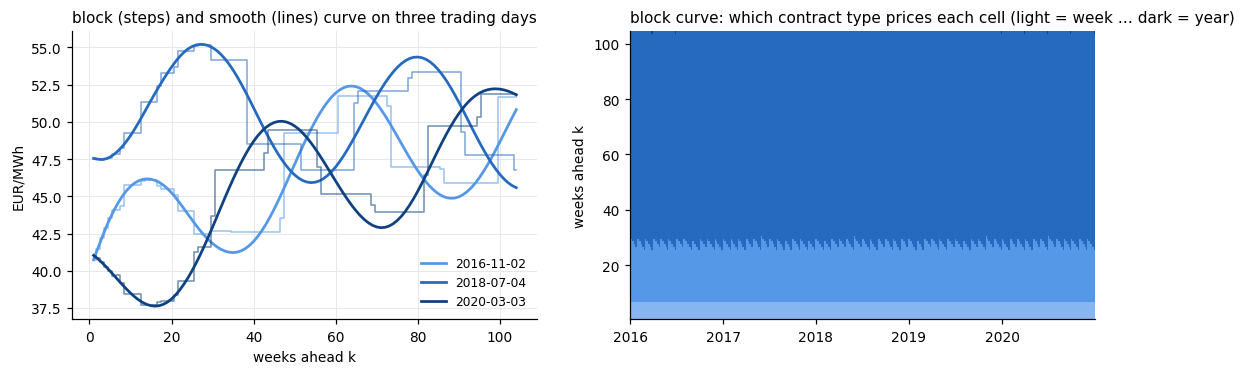

In [3]:
block, block_types = build_block_curve(panel)
smooth, smooth_types = build_smooth_curve(panel, smoothness=SMOOTHNESS)
curve, ctypes = (smooth, smooth_types) if CURVE == "smooth" else (block, block_types)
print(f"block curve: {block.shape[0]} trading days x {block.shape[1]} weeks ahead, {block.notna().mean().mean():.1%} of the cells priced")
print(f"smooth curve: mean |second difference| {np.nanmean(np.abs(np.diff(smooth.values, 2, axis=1))):.3f} EUR/MWh against {np.nanmean(np.abs(np.diff(block.values, 2, axis=1))):.3f} for the block curve")
print("repricing error of the smooth curve by contract type (EUR/MWh):"); print(repricing_error(panel, smooth).round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
days = block.index[[len(block) // 6, len(block) // 2, 5 * len(block) // 6]]
for d, col in zip(days, plots.RAMP[1:]):
    axes[0].step(block.columns, block.loc[d], where="mid", color=col, lw=1.0, alpha=0.6)
    axes[0].plot(smooth.columns, smooth.loc[d], color=col, lw=1.8, label=str(d.date()))
axes[0].set_xlabel("weeks ahead k"); axes[0].set_ylabel("EUR/MWh"); axes[0].set_title("block (steps) and smooth (lines) curve on three trading days"); axes[0].legend()
code = {"W": 0, "M": 1, "Q": 2, "Y": 3}
m = block_types.replace(code).astype(float).values.T
im = axes[1].imshow(np.ma.masked_invalid(m), aspect="auto", origin="lower", cmap=plt.matplotlib.colors.ListedColormap(plots.RAMP), interpolation="nearest",
                    extent=[0, len(block), 0.5, block.shape[1] + 0.5])
yrs = block.index.year; ticks = [i for i in range(len(yrs)) if i == 0 or yrs[i] != yrs[i - 1]]
axes[1].set_xticks(ticks, [yrs[i] for i in ticks]); axes[1].set_ylabel("weeks ahead k"); axes[1].grid(False)
axes[1].set_title("block curve: which contract type prices each cell (light = week … dark = year)");

## 2. Weekly fixed-delivery returns

Sampling on the last trading day of each ISO week, the return of delivery week $k$ is
$r_{t,k} = \log F_t(k) - \log F_{t-1}(k+1)$: the same physical week, one week closer. A return that compares a month price
with a quarter price (the delivery week moved from one contract type to the other) is not a price change and is masked.

smooth curve: 260 weekly observations, 103 maturities, 100.0% of the cells observed


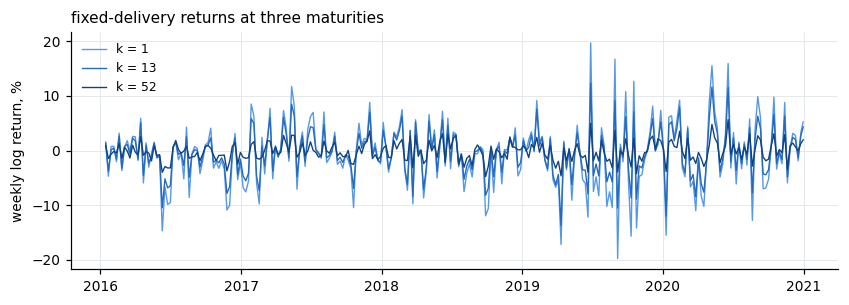

In [4]:
def returns_of(c, t):
    R = weekly_fixed_delivery_returns(c, t)
    if WINDOW[0]: R = R[R.index >= WINDOW[0]]
    if WINDOW[1]: R = R[R.index <= WINDOW[1]]
    return R
R, R_block = returns_of(curve, ctypes), returns_of(block, block_types)
print(f"{CURVE} curve: {len(R)} weekly observations, {R.shape[1]} maturities, {R.notna().mean().mean():.1%} of the cells observed")
fig, ax = plt.subplots(figsize=(9, 2.8))
for k, col in zip((1, 13, 52), plots.RAMP[1:]):
    ax.plot(R.index, R[k] * 100, color=col, lw=0.9, label=f"k = {k}")
ax.set_ylabel("weekly log return, %"); ax.set_title("fixed-delivery returns at three maturities"); ax.legend();

## 3. Principal components

The covariance of the returns across maturities is decomposed with `sklearn.decomposition.PCA`. On the Nordic
system curve the literature finds a dominant level factor (a parallel shift that is larger at the front) and a second
factor that tilts the front against the back; together they carry most of the variance, which is the empirical reason
for a two-factor price model. The **volatility term structure** (bottom right) is the diagonal of the covariance: high at
the front, decaying towards a floor set by the long-term factor.

variance explained by PC1–PC4: [0.945 0.049 0.003 0.002]   (260 weeks, 103 maturities)


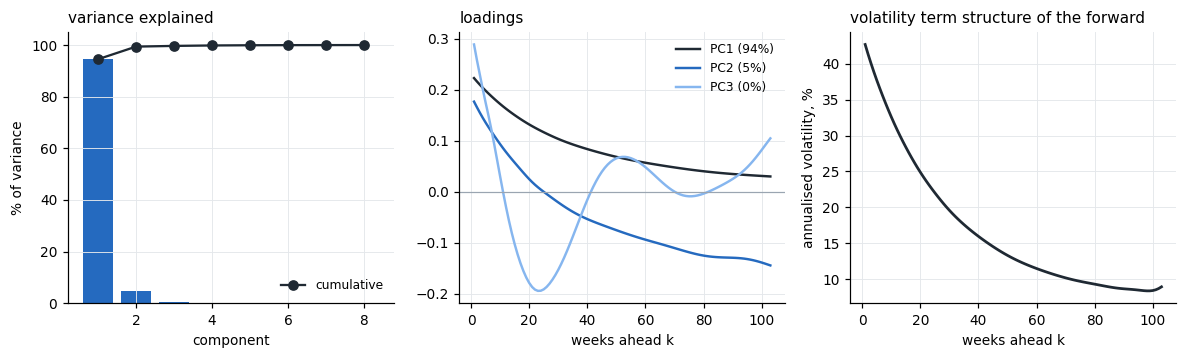

In [5]:
res = pca(R)
k = res["k"]
print("variance explained by PC1–PC4:", np.round(res["share"][:4], 3), f"  ({res['n_weeks']} weeks, {len(k)} maturities)")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].bar(np.arange(1, 9), res["share"][:8] * 100, color=plots.RAMP[2]); axes[0].plot(np.arange(1, 9), np.cumsum(res["share"][:8]) * 100, "o-", color=plots.INK, label="cumulative")
axes[0].set_xlabel("component"); axes[0].set_ylabel("% of variance"); axes[0].set_title("variance explained"); axes[0].legend()
for j, col in enumerate((plots.INK, plots.RAMP[2], plots.RAMP[0])):
    axes[1].plot(k, res["loadings"][:, j], color=col, lw=1.6, label=f"PC{j + 1} ({res['share'][j]:.0%})")
axes[1].axhline(0, color=plots.MUTED, lw=0.8); axes[1].set_xlabel("weeks ahead k"); axes[1].set_title("loadings"); axes[1].legend()
axes[2].plot(k, res["vol"] * np.sqrt(52) * 100, color=plots.INK, lw=1.8)
axes[2].set_xlabel("weeks ahead k"); axes[2].set_ylabel("annualised volatility, %"); axes[2].set_title("volatility term structure of the forward");

## 4. Fitting the two-factor model

The covariance form $\sigma_\xi^2 + \sigma_\chi^2\phi_\chi^{k+j}$ is fitted to the empirical covariance matrix by weighted least
squares (weights $1/(\mathrm{sd}_k \mathrm{sd}_j)$ so that correlations and variances count alike). The estimates are in log
units per week; the price model is additive in EUR/MWh, so they are multiplied by a **reference price level** (the mean of
the curve over the window). The half-life $\log 0.5 / \log \phi_\chi$ says how quickly a short-term shock fades.

block curve for comparison: phi_chi 0.9742, sigma_chi 2.57, sigma_xi 0.51 EUR/MWh, variance reproduced 96.2%, PC1 93.6%
phi_chi = 0.9740 (half-life 26 weeks)
sigma_chi = 0.0563 log/week = 2.62 EUR/MWh at the reference level 46.6
sigma_xi  = 0.0109 log/week = 0.51 EUR/MWh
the fitted covariance reproduces 98.3% of the total variance; vol-curve RMSE 0.5 %/yr
literature (Kleiven et al. 2023, pre-2019 NO3/NO4): phi_chi 0.977, sigma_chi 2.29, sigma_xi 0.55 EUR/MWh; sample truth: 0.977, 2.30, 0.55


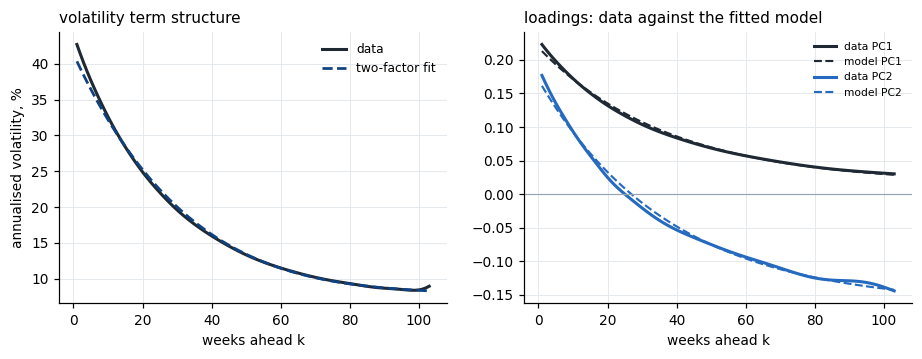

In [6]:
fit = fit_two_factor(res["cov"], k)
LEVEL = float(np.nanmean(curve.loc[R.index[0]:R.index[-1]].values))
res_b = pca(R_block); fit_b = fit_two_factor(res_b["cov"], res_b["k"]); LEVEL_b = float(np.nanmean(block.loc[R_block.index[0]:R_block.index[-1]].values))
print(f"block curve for comparison: phi_chi {fit_b['phi_chi']:.4f}, sigma_chi {fit_b['sigma_chi'] * LEVEL_b:.2f}, sigma_xi {fit_b['sigma_xi'] * LEVEL_b:.2f} EUR/MWh, "
      f"variance reproduced {fit_b['trace_share']:.1%}, PC1 {res_b['share'][0]:.1%}")
params = {"phi_chi": fit["phi_chi"], "sigma_chi": fit["sigma_chi"] * LEVEL, "sigma_xi": fit["sigma_xi"] * LEVEL,
          "reference_level": LEVEL, "sigma_chi_log": fit["sigma_chi"], "sigma_xi_log": fit["sigma_xi"],
          "halflife_weeks": fit["halflife_weeks"], "trace_share": fit["trace_share"], "pc_shares": [float(x) for x in res["share"][:4]],
          "window": [str(R.index[0].date()), str(R.index[-1].date())], "source": str(path.name), "curve": CURVE,
          "block_curve_for_comparison": {"phi_chi": fit_b["phi_chi"], "sigma_chi": fit_b["sigma_chi"] * LEVEL_b, "sigma_xi": fit_b["sigma_xi"] * LEVEL_b, "trace_share": fit_b["trace_share"]}}
save_json(params, PROCESSED / "price_params.json")
print(f"phi_chi = {params['phi_chi']:.4f} (half-life {params['halflife_weeks']:.0f} weeks)")
print(f"sigma_chi = {fit['sigma_chi']:.4f} log/week = {params['sigma_chi']:.2f} EUR/MWh at the reference level {LEVEL:.1f}")
print(f"sigma_xi  = {fit['sigma_xi']:.4f} log/week = {params['sigma_xi']:.2f} EUR/MWh")
print(f"the fitted covariance reproduces {fit['trace_share']:.1%} of the total variance; vol-curve RMSE {fit['vol_rmse_annual_pct']:.1f} %/yr")
print("literature (Kleiven et al. 2023, pre-2019 NO3/NO4): phi_chi 0.977, sigma_chi 2.29, sigma_xi 0.55 EUR/MWh"
      + ("; sample truth: 0.977, 2.30, 0.55" if path != real else ""))
C = fit["model_cov"]
evm, vecm = np.linalg.eigh(C); o = np.argsort(evm)[::-1]; vecm = vecm[:, o]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(k, res["vol"] * np.sqrt(52) * 100, color=plots.INK, lw=2, label="data")
axes[0].plot(k, np.sqrt(np.diag(C)) * np.sqrt(52) * 100, color=plots.RAMP[3], lw=1.8, ls="--", label="two-factor fit")
axes[0].set_xlabel("weeks ahead k"); axes[0].set_ylabel("annualised volatility, %"); axes[0].set_title("volatility term structure"); axes[0].legend()
for j, col in enumerate((plots.INK, plots.RAMP[2])):
    v = vecm[:, j] * np.sign(vecm[0, j])
    axes[1].plot(k, res["loadings"][:, j], color=col, lw=2, label=f"data PC{j + 1}")
    axes[1].plot(k, v, color=col, lw=1.4, ls="--", label=f"model PC{j + 1}")
axes[1].axhline(0, color=plots.MUTED, lw=0.8); axes[1].set_xlabel("weeks ahead k"); axes[1].set_title("loadings: data against the fitted model"); axes[1].legend(fontsize=7);

The parameters of the chosen curve are saved to `data/processed/price_params.json` (the block-curve fit is stored next to
them for comparison) and picked up by notebook 4. On the real data the
pre-2021 window gives values close to the literature; the full sample including the 2021–22 energy crisis roughly doubles
$\sigma_\xi$ and adds a very fast front factor, which is why the calibration window is a modelling choice to report.